Creation des modeles debug...
  Debug model saved : /workspace/weights/debug_fp32.onnx (339 outputs)
  Debug model saved : /workspace/weights/debug_int8.onnx (330 outputs)

Construction des mappings sortie -> node...

Chargement des sessions ONNX...

Preprocessing de l'image : b1c66a42-6f7d68ca.jpg
Inference FP32 (debug)...
  339 tenseurs récupérés
Inference INT8 (debug)...
  330 tenseurs récupérés

Calcul du MSE couche par couche...
  252 couches comparées


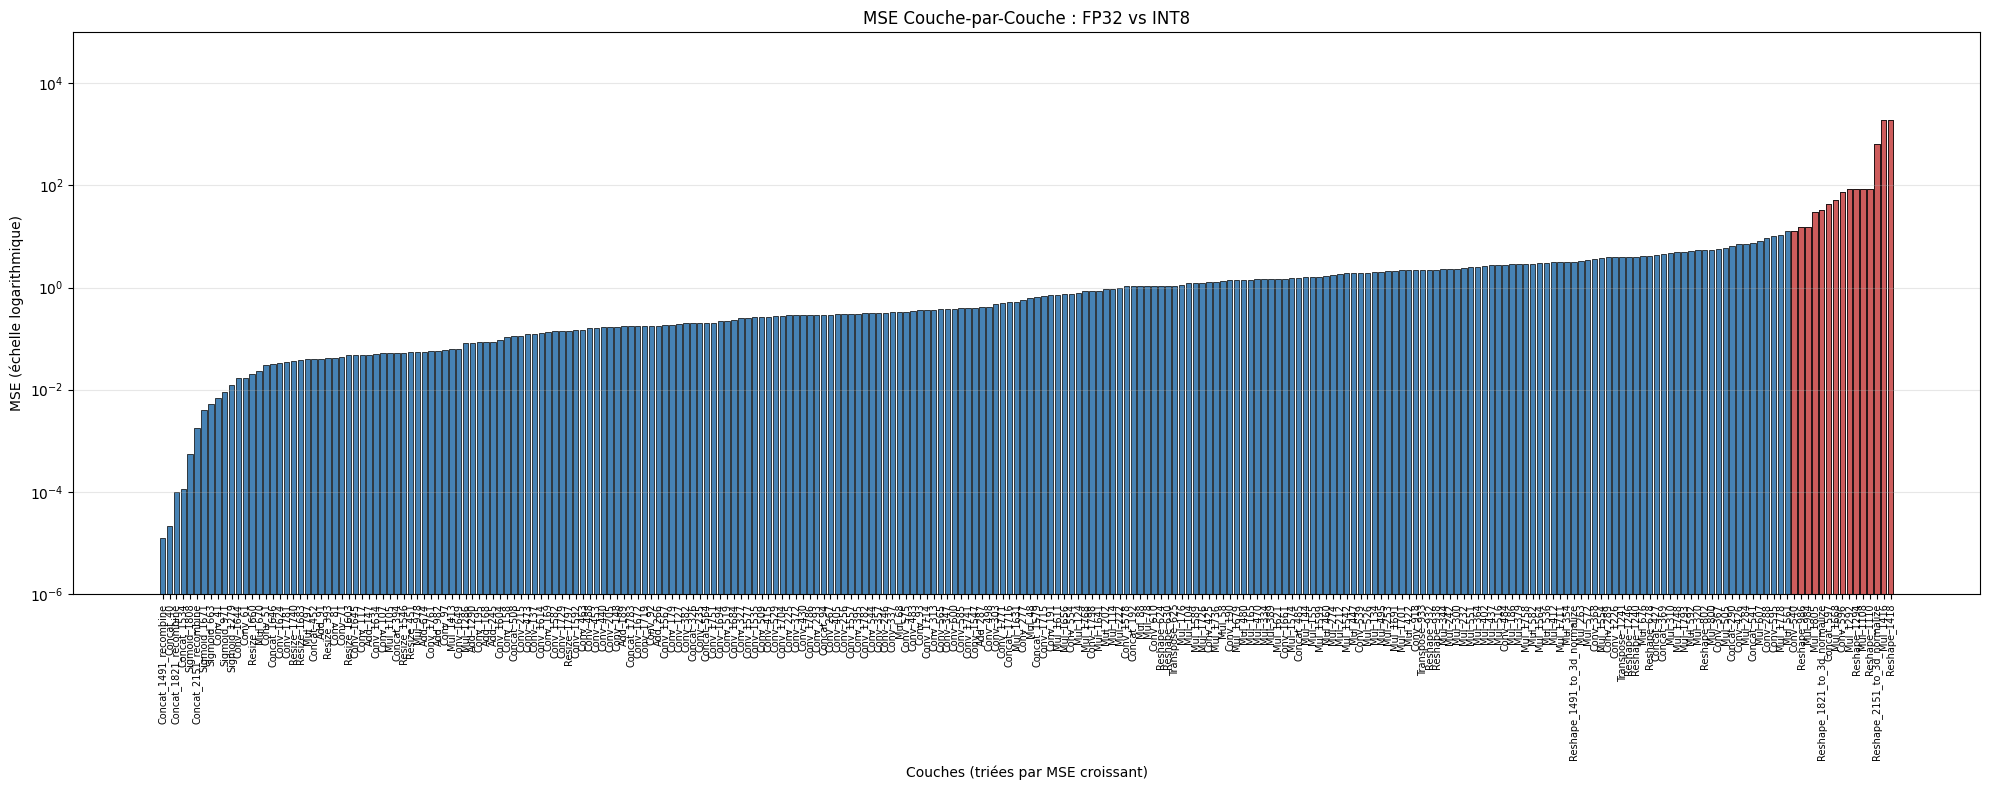


TOP 15 COUCHES PAR MSE (les plus sensibles à la quantification)
   1. Reshape_1418                                            MSE = 1.899230e+03
   2. Mul_1416                                                MSE = 1.897014e+03
   3. Reshape_2151_to_3d_normalize                            MSE = 6.613713e+02
   4. Reshape_1110                                            MSE = 8.558862e+01
   5. Mul_1108                                                MSE = 8.535263e+01
   6. Reshape_1294                                            MSE = 8.488289e+01
   7. Mul_1292                                                MSE = 8.488289e+01
   8. Conv_596                                                MSE = 7.495575e+01
   9. Mul_1668                                                MSE = 5.149855e+01
  10. Concat_597                                              MSE = 4.301949e+01
  11. Reshape_1821_to_3d_normalize                            MSE = 3.360232e+01
  12. Mul_1805                              

In [1]:
# %% [markdown]
# # ============= MSE COUCHE-PAR-COUCHE : FP32 vs INT8 =============
# %%
import os
import sys
import cv2
import numpy as np
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.append(os.getcwd())

# %% [markdown]
# # ============= CONSTANTES DE CONFIGURATION =============
# %%
IMG_SIZE = 640
TARGET_IMG = "b1c66a42-6f7d68ca.jpg"

BASE_DIR = os.getcwd()
VAL_DIR = os.path.join(BASE_DIR, "dataset/images/val")

ONNX_FP32_PATH = os.path.join(BASE_DIR, "weights/yolop-640-640-normalized.onnx")
ONNX_INT8_PATH = os.path.join(BASE_DIR, "weights/yolop-640-640-normalized-quantized-int8-Entropy.onnx")

DEBUG_FP32_PATH = os.path.join(BASE_DIR, "weights/debug_fp32.onnx")
DEBUG_INT8_PATH = os.path.join(BASE_DIR, "weights/debug_int8.onnx")

TARGET_OPS = [
    'Conv', 'QLinearConv', 'ConvInteger',
    'Gemm', 'MatMul', 'QLinearMatMul',
    'Add', 'Mul', 'Concat',
    'Sigmoid', 'Relu', 'HardSwish',
    'Resize', 'Transpose', 'Reshape'
]

MSE_PLOT_TOP_N = 15
MSE_PLOT_FIGSIZE = (20, 8)
MSE_YLIM_PADDING_DECADES = 1

# %% [markdown]
# # ============= CREATION MODELE DEBUG =============
# %%
def create_debug_model(input_model_path, output_model_path):
    if os.path.exists(output_model_path):
        os.remove(output_model_path)

    model = onnx.load(input_model_path)
    if model.opset_import[0].version < 13:
        model.opset_import[0].version = 13

    intermediate_outputs = []
    for node in model.graph.node:
        if node.op_type in TARGET_OPS:
            for output in node.output:
                if output:
                    intermediate_outputs.append(output)

    existing_outputs = {o.name for o in model.graph.output}
    for output_name in intermediate_outputs:
        if output_name not in existing_outputs:
            model.graph.output.append(
                onnx.helper.make_tensor_value_info(output_name, onnx.TensorProto.FLOAT, None)
            )

    onnx.save(model, output_model_path)
    print(f"  Debug model saved : {output_model_path} ({len(model.graph.output)} outputs)")
    return output_model_path


# %% [markdown]
# # ============= MAPPING SORTIE -> NODE NAME =============
# %%
def build_output_to_node_map(model_path):
    model = onnx.load(model_path)
    output_to_node = {}
    for node in model.graph.node:
        for out in node.output:
            output_to_node[out] = node.name if node.name else f"{node.op_type}_{out}"
    return output_to_node


# %% [markdown]
# # ============= PREPROCESSING =============
# %%
def letterbox(img, new_shape=IMG_SIZE):
    shape = img.shape[:2]
    if isinstance(new_shape, int):
        new_shape = (new_shape, new_shape)
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
    dw = (new_shape[1] - new_unpad[0]) // 2
    dh = (new_shape[0] - new_unpad[1]) // 2
    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
    top, bottom = dh, new_shape[0] - new_unpad[1] - dh
    left, right = dw, new_shape[1] - new_unpad[0] - dw
    img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
    return img


def preprocess(img_path):
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_lb = letterbox(img_rgb, IMG_SIZE)
    img_input = img_lb.astype(np.float32) / 255.0
    img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)
    return img_input


# %% [markdown]
# # ============= INFERENCE DEBUG (TOUTES LES SORTIES) =============
# %%
def run_debug_inference(session, img_input):
    output_names = [o.name for o in session.get_outputs()]
    outputs = session.run(output_names, {session.get_inputs()[0].name: img_input})
    return dict(zip(output_names, outputs))


# %% [markdown]
# # ============= CALCUL MSE COUCHE PAR COUCHE =============
# %%
def compute_mse_per_layer(outputs_fp32, outputs_int8, output_to_node_fp32, output_to_node_int8):
    common_tensors = set(outputs_fp32.keys()) & set(outputs_int8.keys())

    mse_results = []
    for tensor_name in common_tensors:
        fp32_val = outputs_fp32[tensor_name]
        int8_val = outputs_int8[tensor_name]

        if fp32_val.shape != int8_val.shape:
            continue
        if fp32_val.size == 0:
            continue

        mse = float(np.mean((fp32_val.astype(np.float64) - int8_val.astype(np.float64)) ** 2))

        node_name = output_to_node_fp32.get(tensor_name, tensor_name)
        mse_results.append((node_name, tensor_name, mse))

    mse_results.sort(key=lambda x: x[2])
    return mse_results


# %% [markdown]
# # ============= PLOT MSE =============
# %%
def plot_mse(mse_results):
    if not mse_results:
        print("Aucun tenseur commun trouvé entre les deux modèles.")
        return

    labels = [r[0] for r in mse_results]
    values = [r[2] for r in mse_results]
    x = np.arange(len(labels))

    nonzero_values = [v for v in values if v > 0]
    if nonzero_values:
        log_min = np.floor(np.log10(min(nonzero_values))) - MSE_YLIM_PADDING_DECADES
        log_max = np.ceil(np.log10(max(values))) + MSE_YLIM_PADDING_DECADES
    else:
        log_min, log_max = -8, 0

    fig, ax = plt.subplots(figsize=MSE_PLOT_FIGSIZE)
    ax.bar(x, values, color='steelblue', edgecolor='black', linewidth=0.5)
    ax.set_yscale('log')
    ax.set_ylim(10**log_min, 10**log_max)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_xlabel('Couches (triées par MSE croissant)')
    ax.set_ylabel('MSE (échelle logarithmique)')
    ax.set_title('MSE Couche-par-Couche : FP32 vs INT8')
    ax.grid(True, axis='y', alpha=0.3, which='both')

    if len(mse_results) > MSE_PLOT_TOP_N:
        threshold = mse_results[-MSE_PLOT_TOP_N][2]
        for i, v in enumerate(values):
            if v >= threshold:
                ax.bar(i, v, color='indianred', edgecolor='black', linewidth=0.5)

    plt.tight_layout()
    plt.show()

    print(f"\n{'='*70}")
    print(f"TOP {MSE_PLOT_TOP_N} COUCHES PAR MSE (les plus sensibles à la quantification)")
    print(f"{'='*70}")
    for rank, (node_name, tensor_name, mse) in enumerate(reversed(mse_results[-MSE_PLOT_TOP_N:]), 1):
        print(f"  {rank:2d}. {node_name:55s} MSE = {mse:.6e}")
    print(f"{'='*70}")
    print(f"  Couche la plus stable  : {mse_results[0][0]} (MSE = {mse_results[0][2]:.6e})")
    print(f"  Couche la plus sensible: {mse_results[-1][0]} (MSE = {mse_results[-1][2]:.6e})")
    print(f"  Ratio max/min          : {mse_results[-1][2] / max(mse_results[0][2], 1e-30):.2e}")
    print(f"{'='*70}")


# %% [markdown]
# # ============= MAIN =============
# %%
if __name__ == "__main__":
    target_path = os.path.join(VAL_DIR, TARGET_IMG)

    if not os.path.exists(target_path):
        print(f"Image introuvable : {target_path}")
        raise SystemExit(1)
    if not os.path.exists(ONNX_FP32_PATH):
        print(f"Modele FP32 introuvable : {ONNX_FP32_PATH}")
        raise SystemExit(1)
    if not os.path.exists(ONNX_INT8_PATH):
        print(f"Modele INT8 introuvable : {ONNX_INT8_PATH}")
        raise SystemExit(1)

    print("Creation des modeles debug...")
    create_debug_model(ONNX_FP32_PATH, DEBUG_FP32_PATH)
    create_debug_model(ONNX_INT8_PATH, DEBUG_INT8_PATH)

    print("\nConstruction des mappings sortie -> node...")
    output_to_node_fp32 = build_output_to_node_map(DEBUG_FP32_PATH)
    output_to_node_int8 = build_output_to_node_map(DEBUG_INT8_PATH)

    print("\nChargement des sessions ONNX...")
    sess_options = ort.SessionOptions()
    sess_options.log_severity_level = 3
    providers = ['CPUExecutionProvider']

    session_fp32 = ort.InferenceSession(DEBUG_FP32_PATH, sess_options=sess_options, providers=providers)
    session_int8 = ort.InferenceSession(DEBUG_INT8_PATH, sess_options=sess_options, providers=providers)

    print(f"\nPreprocessing de l'image : {TARGET_IMG}")
    img_input = preprocess(target_path)

    print("Inference FP32 (debug)...")
    outputs_fp32 = run_debug_inference(session_fp32, img_input)
    print(f"  {len(outputs_fp32)} tenseurs récupérés")

    print("Inference INT8 (debug)...")
    outputs_int8 = run_debug_inference(session_int8, img_input)
    print(f"  {len(outputs_int8)} tenseurs récupérés")

    print("\nCalcul du MSE couche par couche...")
    mse_results = compute_mse_per_layer(outputs_fp32, outputs_int8, output_to_node_fp32, output_to_node_int8)
    print(f"  {len(mse_results)} couches comparées")

    plot_mse(mse_results)